### Lab 4 - Divide and Conquer Algorithms

**Jack LeCloux, Karl Kosterkiewicz**

**CSC 3310 002**

### Implementation

In [58]:
import random

def find_kth_smallest(arr, k):
    '''Find the kth smallest element using a recursive approach'''

    pivot = random.choice(arr)

    smaller = []
    equal = []
    larger = []

    for value in arr:
        if value < pivot:
            smaller.append(value)
        elif value > pivot:
            larger.append(value)
        else:
            equal.append(value)

    if k <= len(smaller):
        return find_kth_smallest(smaller, k)

    if k <= len(smaller) + len(equal):
        return pivot

    return find_kth_smallest(larger, k - len(smaller) - len(equal))

In [4]:
def find_kth_smallest_sorting(arr, k):
    '''Finds the kth smallest element using the sorting approach'''
    sorted_arr = sorted(arr)
    return sorted_arr[k - 1]

### Testing

In [59]:
def test(arr, k, method, expected, msg):
    result = method(arr, k)
    assert result == expected, f"{msg}: expected {expected}, got {result}"
    return True

In [60]:
test_cases = [
    ("Random list", [5, 1, 6, 7, 3, 4, 8]),
    ("Already sorted", [1, 2, 3, 4, 5]),
    ("Reverse sorted", [5, 4, 3, 2, 1]),
    ("Two elements", [9, -2]),
    ("Duplicates", [4, 1, 4, 2, 4, 2]),
    ("All values equal", [7, 7, 7, 7]),
    ("Negative and positive", [-8, 3, -1, 0, 6, -4]),
    ("Floating-point values", [2.5, -1.5, 0.0, 2.5]),
]

for case_name, values in test_cases:
    passed_vals = 0
    for k in range(1, len(values) + 1):
        expected = sorted(values)[k - 1]
        if(test(values, k, find_kth_smallest, expected, f"{case_name}, k={k}")):
            passed_vals += 1
    print(f"{case_name}: passed {passed_vals} out of {len(values)} tests")

Random list: passed 7 out of 7 tests
Already sorted: passed 5 out of 5 tests
Reverse sorted: passed 5 out of 5 tests
Two elements: passed 2 out of 2 tests
Duplicates: passed 6 out of 6 tests
All values equal: passed 4 out of 4 tests
Negative and positive: passed 6 out of 6 tests
Floating-point values: passed 4 out of 4 tests


### Benchmarking

In [37]:
import time

def benchmark(arr, k, method):
    start_time = time.time()
    method(arr, k)
    elapsed_time = time.time() - start_time
    return elapsed_time

In [43]:
times = {}

for i in range(1, 1000000, 10000):
    random_list = [random.randint(-1_000_000, 1_000_000) for _ in range(i)]
    k = random.randint(1, i)
    times[i] = [benchmark(random_list, k, find_kth_smallest), benchmark(random_list, k, find_kth_smallest_sorting)]

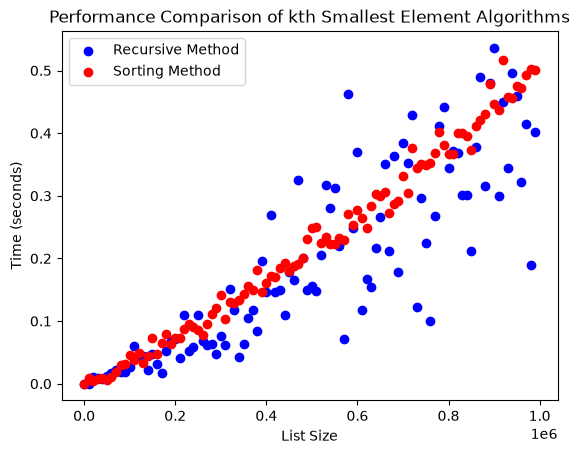

In [44]:
import matplotlib.pyplot as plt

plt.scatter(list(times.keys()), [t[0] for t in times.values()], label='Recursive Method', color='blue')
plt.scatter(list(times.keys()), [t[1] for t in times.values()], label='Sorting Method', color='red')
plt.xlabel('List Size')
plt.ylabel('Time (seconds)')
plt.title('Performance Comparison of kth Smallest Element Algorithms')
plt.legend()

In [57]:
import numpy as np
from scipy.stats import linregress

list_sizes = np.array(list(times.keys()))
run_times_recursive = np.array([times[i][0] for i in list_sizes])
run_times_sorting = np.array([times[i][1] for i in list_sizes])

m1, b1, _, _, _ = linregress(np.log(list_sizes[5:]), np.log(run_times_recursive[5:]))
m2, b2, _, _, _ = linregress(np.log(list_sizes[5:]), np.log(run_times_sorting[5:]))

print(f"Slope for recursive method: {m1:.2f}")
print(f"Slope for sorting method: {m2:.2f}")

Slope for recursive method: 1.20
Slope for sorting method: 1.23
